# 06 · CI/CD — SageMaker Pipeline and GitHub Actions
**AAI-540 Group 3 — CloudTrail Suspicious-Activity Classifier**

| | |
|---|---|
| **Goal** | Automate retraining and release: every run re-validates the data, retrains, evaluates and **only registers a model that passes the quality gate**. Show the DAG in a **successful** and a **failed** state. |
| **Input (S3)** | `features/csv/feature_mart.csv` (notebook 02) · `pipelines/best_hyperparameters.json` (notebook 03) |
| **Output** | Pipeline `cloudtrail-risk-pipeline` · new `PendingManualApproval` version in `cloudtrail-risk-models` |

### The two halves of CI/CD in this project
| | where | trigger | what it checks |
|---|---|---|---|
| **CI** (continuous integration) | GitHub Actions — `.github/workflows/ci.yml` | every push / pull request | code style (ruff) + unit tests: ingestion, leakage-free features, chronological split, encoder, metrics, gate logic |
| **CD** (continuous delivery / training) | SageMaker Pipelines — `pipelines/pipeline.py` | new data, drift alarm, or a merge to `main` (started from Studio) | data quality → train → evaluate → **quality gate** → register (manual approval before deploy) |

> **Learner Lab note:** lab credentials are temporary and IAM users cannot be created, so GitHub Actions cannot call AWS. CI therefore runs the tests in GitHub, and the SageMaker pipeline is started from Studio (this notebook, or `python pipelines/pipeline.py --role-arn ... --start` in a Studio terminal).

### The DAG
```
ValidateAndPreprocess ──► TrainModel ──► EvaluateModel ──► QualityGate ──► RegisterModel        (gate passed)
   data-quality checks      built-in        thresholds on       ROC-AUC ≥ 0.80         PendingManualApproval
   + split + encode         XGBoost         2019, metrics        AND AP lift ≥ 5x
                                            on 2020                     └──► QualityGateFailed  (pipeline fails)
```
Each step runs as a separate, short-lived `ml.m5.large` job (~15–20 minutes per execution end-to-end).

## 1. Setup

In [1]:
%%capture pip_log
# Install the project's pinned libraries (run once per kernel, BEFORE any other import).
# The pin keeps the SageMaker Python SDK on v2, which all notebooks in this repo use.
# Output is captured to keep the notebook clean; run print(pip_log.stdout) to see it.
# (Warnings about sagemaker-core / sagemaker-mlops conflicts refer to Studio's pre-installed
#  SDK v3 packages, which this project does not use.)
%pip install -q -r ../requirements.txt

In [2]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))   # shared project package: src/cloudtrail_mlops
DATA_DIR = Path.home() / "cloudtrail-data"           # local working copy, outside the git repo
DATA_DIR.mkdir(exist_ok=True)
os.environ["SAGEMAKER_SUPPRESS_V2_WARNING"] = "1"         # we intentionally pin SDK v2 (see requirements.txt)

import json
import time

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "pipelines"))
from cloudtrail_mlops import aws
from pipeline import MODEL_PACKAGE_GROUP, get_pipeline, hyperparameters

ctx = aws.get_context()
state = aws.load_state(ctx)
sm_client = ctx.session.sagemaker_client
print("Hyper-parameters used by the pipeline:", json.dumps(hyperparameters(), indent=1))

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml
Hyper-parameters used by the pipeline: {
 "objective": "binary:logistic",
 "eval_metric": "aucpr",
 "num_round": 400,
 "early_stopping_rounds": 40,
 "max_depth": 6,
 "eta": 0.044241396722974426,
 "subsample": 0.5167504191000817,
 "colsample_bytree": 0.45223113672559395,
 "min_child_weight": 1.3608051865732016,
 "gamma": 2.9455573066665357,
 "lambda": 2.2852990661057127,
 "scale_pos_weight": 5,
 "alpha": 0.11359090013332653
}


## 2. Create (or update) the pipeline definition

In [3]:
pipeline = get_pipeline(role=ctx.role, bucket=ctx.bucket)
pipeline.upsert(role_arn=ctx.role, description="CloudTrail risk model: validate -> train -> evaluate -> gate -> register")
definition = json.loads(pipeline.definition())
print("Pipeline:", pipeline.name)
pd.DataFrame([{"step": s["Name"], "type": s["Type"]} for s in definition["Steps"]] +
             [{"step": s["Name"], "type": s["Type"] + " (branch)"} for s in definition["Steps"][-1]["Arguments"].get("IfSteps", []) + definition["Steps"][-1]["Arguments"].get("ElseSteps", [])])

/opt/conda/lib/python3.12/site-packages/sagemaker/workflow/pipeline_context.py:340: UserWarning: Running within a PipelineSession, there will be No Wait, No Logs, and No Job being started.
  warnings.warn(
INFO:sagemaker.image_uris:Ignoring unnecessary instance type: None.
INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.
INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information

Pipeline: cloudtrail-risk-pipeline


,step,type
0,ValidateAndPreprocess,Processing
1,TrainModel,Training
2,EvaluateModel,Processing
3,QualityGate,Condition
4,RegisterModel-RegisterModel,RegisterModel (branch)
5,QualityGateFailed,Fail (branch)


## 3. Start two executions
* **Run A — real release gate** (ROC-AUC ≥ 0.80, AP lift ≥ 5×) → expected **Succeeded** with a new model version registered.
* **Run B — impossible gate** (ROC-AUC ≥ 0.999) → the same trained model is rejected → expected **Failed** at `QualityGateFailed`, nothing registered.

Both run in parallel. Open **Studio → Pipelines → cloudtrail-risk-pipeline → Executions** to watch the DAG live (this is the view to show in the video).

In [4]:
run_pass = pipeline.start(execution_display_name="release-gate", parameters={})
run_fail = pipeline.start(execution_display_name="impossible-gate", parameters={"MinTestRocAuc": 0.999})
aws.save_state(ctx, pipeline_name=pipeline.name, pipeline_executions=[run_pass.arn, run_fail.arn])
print("Run A:", run_pass.arn.split("/")[-1], "\nRun B:", run_fail.arn.split("/")[-1])

INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.
INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.


Run A: gg6nic9d3pj9 
Run B: 7uxp0egse2cs


In [5]:
def wait(execution, label):
    while True:
        status = execution.describe()["PipelineExecutionStatus"]
        if status not in ("Executing", "Stopping"):
            return status
        print(time.strftime("%H:%M:%S"), label, status)
        time.sleep(60)


results = {"Run A (release gate)": wait(run_pass, "Run A"), "Run B (impossible gate)": wait(run_fail, "Run B")}
results

00:23:12 Run A Executing
00:24:12 Run A Executing
00:25:12 Run A Executing
00:26:12 Run A Executing
00:27:12 Run A Executing
00:28:12 Run A Executing
00:29:13 Run A Executing
00:30:13 Run A Executing
00:31:13 Run A Executing
00:32:13 Run A Executing
00:33:13 Run A Executing
00:34:13 Run A Executing
00:35:13 Run A Executing
00:36:13 Run A Executing


{'Run A (release gate)': 'Succeeded', 'Run B (impossible gate)': 'Failed'}

## 4. Inspect both executions

,step,status,duration_min,failure_reason
0,ValidateAndPreprocess,Succeeded,5.100000,
1,TrainModel,Succeeded,3.100000,
2,EvaluateModel,Succeeded,5.100000,
3,QualityGate,Succeeded,0.000000,
4,RegisterModel-RegisterModel,Succeeded,0.000000,


,step,status,duration_min,failure_reason
0,ValidateAndPreprocess,Succeeded,5.100000,
1,TrainModel,Succeeded,3.100000,
2,EvaluateModel,Succeeded,5.100000,
3,QualityGate,Succeeded,0.000000,
4,QualityGateFailed,Failed,0.000000,Model rejected: test ROC-AUC must be >= 0.999 and test AP lift must be >= 5.0


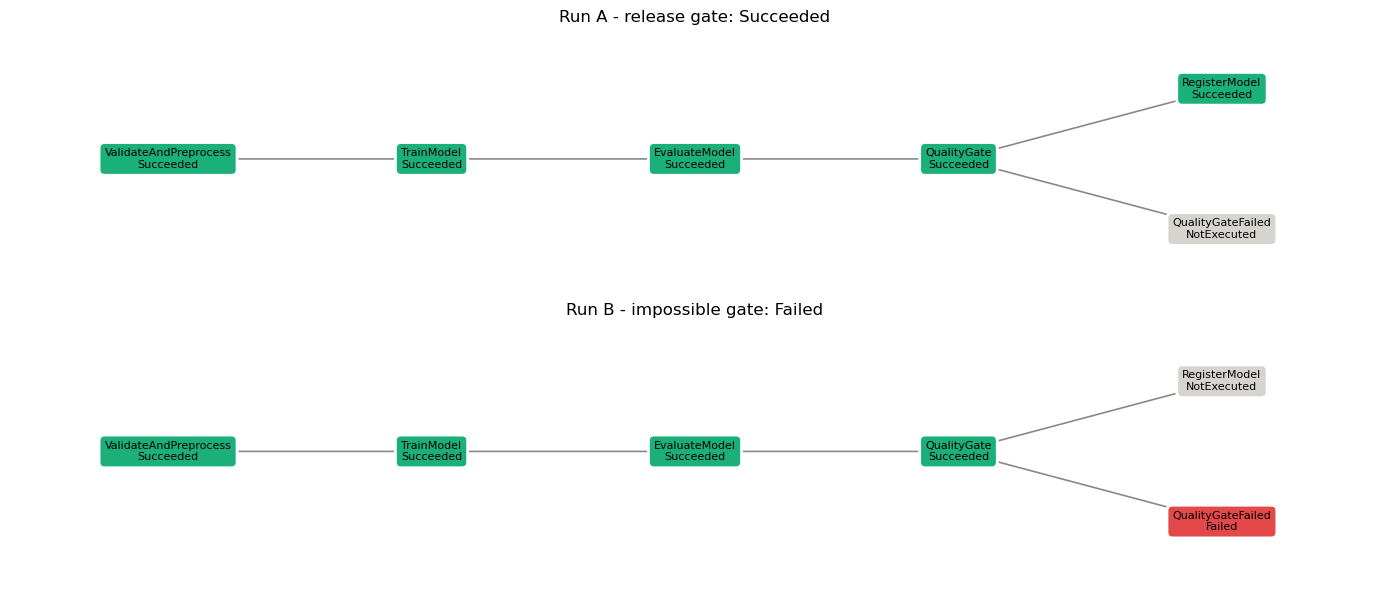

In [6]:
COLOURS = {"Succeeded": "#1baf7a", "Failed": "#e34948", "Executing": "#eda100", "NotExecuted": "#d5d4cf"}
POSITIONS = {"ValidateAndPreprocess": (0, 0), "TrainModel": (1, 0), "EvaluateModel": (2, 0), "QualityGate": (3, 0),
             "RegisterModel-RegisterModel": (4, 0.6), "QualityGateFailed": (4, -0.6)}


def step_table(execution):
    return pd.DataFrame([{"step": s["StepName"], "status": s["StepStatus"],
                          "duration_min": round((s["EndTime"] - s["StartTime"]).total_seconds() / 60, 1) if s.get("EndTime") else None,
                          "failure_reason": (s.get("FailureReason") or "")[:90]}
                         for s in execution.list_steps()][::-1])


def draw_dag(ax, steps, title):
    status = dict(zip(steps.step, steps.status))
    for a, b in [("ValidateAndPreprocess", "TrainModel"), ("TrainModel", "EvaluateModel"), ("EvaluateModel", "QualityGate"),
                 ("QualityGate", "RegisterModel-RegisterModel"), ("QualityGate", "QualityGateFailed")]:
        ax.annotate("", xy=POSITIONS[b], xytext=POSITIONS[a], arrowprops=dict(arrowstyle="->", color="#8a8984", lw=1.2))
    for name, (x, y) in POSITIONS.items():
        state_ = status.get(name, "NotExecuted")
        ax.text(x, y, f"{name.replace('-RegisterModel', '')}\n{state_}", ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.5", fc=COLOURS.get(state_, "#d5d4cf"), ec="white", lw=2))
    ax.set(xlim=(-0.6, 4.6), ylim=(-1.1, 1.1), title=title)
    ax.axis("off")


fig, axes = plt.subplots(2, 1, figsize=(14, 6))
for ax, (label, execution) in zip(axes, (("Run A - release gate", run_pass), ("Run B - impossible gate", run_fail))):
    steps = step_table(execution)
    display(steps.style.set_caption(label))
    draw_dag(ax, steps, f"{label}: {execution.describe()['PipelineExecutionStatus']}")
plt.tight_layout()
plt.show()

### 4.1 The metrics the gate decided on

In [7]:
evaluation_step = next(s for s in run_pass.list_steps() if s["StepName"] == "EvaluateModel")
job_arn = evaluation_step["Metadata"]["ProcessingJob"]["Arn"]
output_uri = sm_client.describe_processing_job(ProcessingJobName=job_arn.split("/")[-1])["ProcessingOutputConfig"]["Outputs"][0]["S3Output"]["S3Uri"]
report = json.loads(ctx.session.read_s3_file(output_uri.split("/")[2], "/".join(output_uri.split("/")[3:]) + "/evaluation.json"))
pd.Series({**report["metrics"], "gate (default thresholds)": report["quality_gate"]["passed"]}, name="value").to_frame()

,value
test_roc_auc,0.958668
test_average_precision,0.33121
test_ap_lift,58.725772
test_recall_medium,0.752475
gate (default thresholds),True


### 4.2 Model Registry after the pipeline runs

In [8]:
versions = sm_client.list_model_packages(ModelPackageGroupName=MODEL_PACKAGE_GROUP, SortBy="CreationTime", SortOrder="Descending")
pd.DataFrame(versions["ModelPackageSummaryList"])[["ModelPackageVersion", "ModelApprovalStatus", "CreationTime", "ModelPackageDescription"]]

,ModelPackageVersion,ModelApprovalStatus,CreationTime,ModelPackageDescription
0,2,PendingManualApproval,2026-10-18 00:36:27.955000+00:00,CloudTrail actor x 5-minute window risk model ...
1,1,Approved,2026-10-17 22:57:49.294000+00:00,XGBoost actor x 5-min window risk model | test...


**Result.** Run A **Succeeded**: every step passed and version **2** of `cloudtrail-risk-models` was registered as **PendingManualApproval** — the continuous-delivery hand-off: a reviewer compares its metrics with the deployed version in Studio and approves it, after which notebook 04's deployment cells (or an EventBridge rule on the approval event, in a production account) roll it out. Run B **Failed** at `QualityGateFailed` with the message *"Model rejected: test ROC-AUC must be >= 0.999 and test AP lift must be >= 5.0"* and registered nothing.

The model retrained by the pipeline reproduces notebook 03 **exactly** (test ROC-AUC 0.9587, AP 0.3312, AP lift 58.7×, recall 75.2 % at the MEDIUM threshold): the pipeline, the notebooks and the endpoint share one code base (`src/cloudtrail_mlops`) and one set of hyper-parameters (`pipelines/best_hyperparameters.json`), so training is reproducible end to end.

## 5. Summary
* **CI:** GitHub Actions runs linting and unit tests on every push and pull request (see the *Actions* tab of the repository).
* **CD:** a 5-step SageMaker Pipeline (ValidateAndPreprocess 5 min → TrainModel 3 min → EvaluateModel 5 min → QualityGate → RegisterModel / QualityGateFailed) re-validates data, retrains, evaluates and enforces the release gate — demonstrated in a **successful** and a **failed** state.
* Pipeline jobs stop automatically — nothing in this notebook keeps billing after the executions finish.